# YOLOv8 Evaluation Report — Extended (Interactive)

This notebook calls report_utils functions.

In [1]:
from report_utils import *

%load_ext autoreload
%autoreload 2

.env


## Section A — Global performance (baseline)

**Description:** Global metrics from YOLO validation (box and pose). Use this as the baseline for regression tracking across checkpoints. These numbers should match the Ultralytics `results_dict` output and reflect the model's overall operating point.


In [2]:
section_a_global_metrics()

,Precision,Recall,F1,mAP
box,0.916,0.897,0.907,0.729
pos,0.940,0.927,0.933,0.953


## Section B — Frame-level performance distribution

**Description:** Distribution of frame-level F1 scores. This reveals whether errors are concentrated in a few catastrophic frames or spread across the dataset. Use the histogram and bins to define investigation thresholds.


**Plot:** Histogram of per-frame F1 scores to show the overall spread and tail behavior.


In [3]:
section_b_f1_distribution()

,count,percent
F1_bin,,
"(0.0, 0.1]",1,0.704225
"(0.1, 0.2]",0,0.000000
"(0.2, 0.3]",0,0.000000
"(0.3, 0.4]",2,1.408451
"(0.4, 0.5]",3,2.112676
"(0.5, 0.6]",3,2.112676
"(0.6, 0.7]",12,8.450704
"(0.7, 0.8]",9,6.338028
"(0.8, 0.9]",3,2.112676


**Table:** Count and percent of frames in each F1 range to quantify how many frames fall below a quality threshold.


## Section C — Top-N worst frames

**Description:** The lowest‑F1 frames with their attributes for targeted debugging. The grid below shows the rendered images from `val/viz` so you can review qualitative errors side‑by‑side.


,img_id,P,R,F1,camera_height,num_gt_detections,scene_density
93,4.2_batch1____4.2_H277_menivim_1_15.jpg,0.000000,0.0,0.000000,277.0,2,sparse
95,4.2_batch1____4.2_H277_menivim_62.jpg,0.250000,0.5,0.333333,277.0,2,sparse
96,4.2_batch1____4.2_H277_menivim_98.jpg,0.333333,0.5,0.400000,277.0,2,sparse
122,4.2_batch2____4.2_H_cam_272_spacesbooth_81.jpg,0.500000,0.4,0.444444,272.0,5,medium
92,4.2_batch1____4.2_H260_menivim_5.jpg,0.500000,0.5,0.500000,260.0,2,sparse
66,4.2_batch3____4.2_H_cam_272_spacesbooth_82.jpg,0.666667,0.4,0.500000,272.0,5,medium


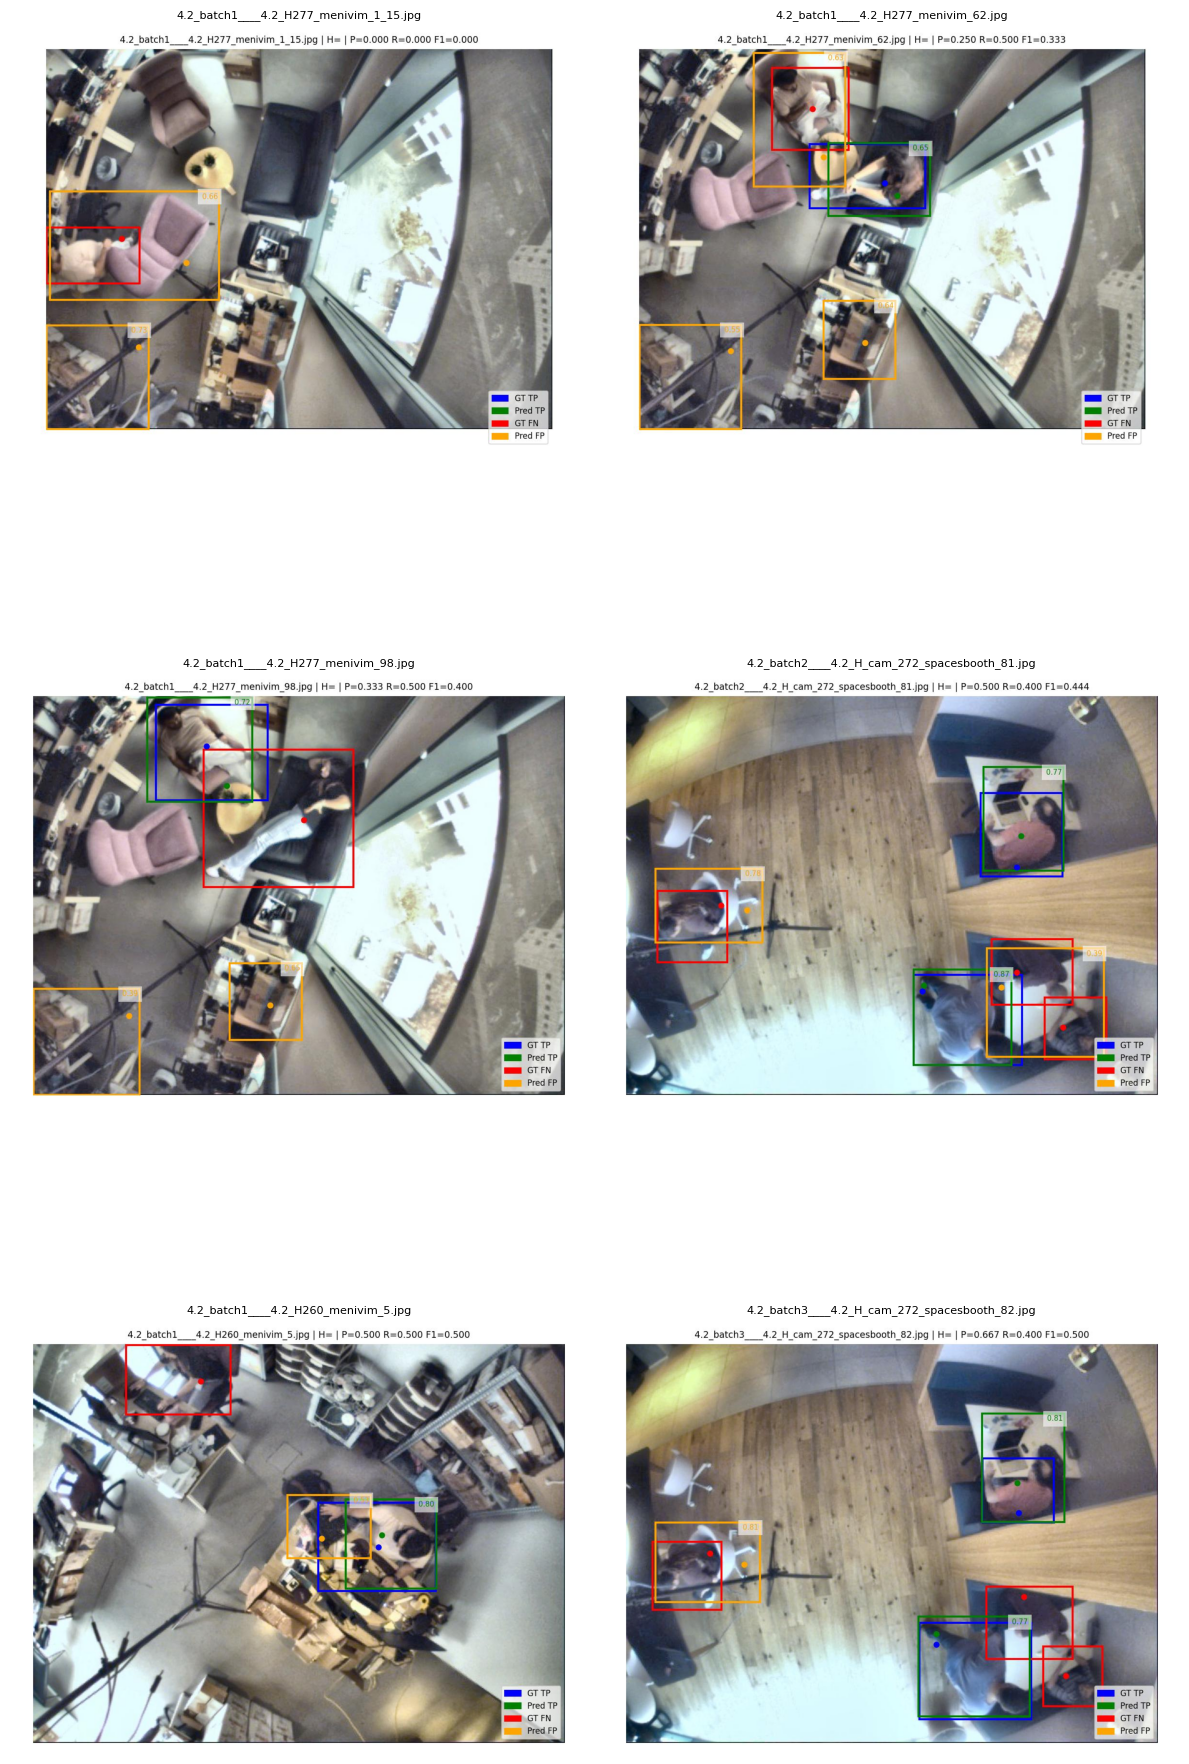

In [4]:
section_c_top_n()

## Section D1 — GT-centric (recall-oriented)

**Description:** Attribute‑level recall for GT detections. This answers “which types of people are missed?” by posture, occlusion type, and their combination.


**Tables:** Recall by posture, occluded_by_object, occluded_by_person, plus the combined 3‑attribute slice (only rows with all attributes present).


In [5]:
section_d1_gt_recall()

,recall
posture,
Leaning Backward,1.00000
Leaning Forward,0.77551
Lying,0.00000
Sitting,1.00000
Sitting Regularly,0.87500
Standing,0.96648


,recall
occluded_by_object,
False,0.970238
True,0.866109


,recall
occluded_by_person,
False,0.917738
True,0.722222


recall
posture           occluded_by_object occluded_by_person          
Leaning Backward  False              False               1.000000
                  True               False               1.000000
                                     True                1.000000
Leaning Forward   False              False               0.875000
                  True               False               0.815789
                                     True                0.000000
Lying             False              False               0.000000
Sitting           False              False               1.000000
                                     True                1.000000
                  True               False               1.000000
Sitting Regularly False              False               1.000000
                                     True                1.000000
                  True               False               0.852459
                                     True                0.857143
Standing          False              False               0.983607
                                     True                0.666667
                  True               False               0.943396
                                     True                1.000000

## Section E — Error composition analysis

**Description:** Composition of false negatives by attribute. This highlights dominant failure modes in terms of posture and occlusion, and their intersections.


**Tables:** FN counts by posture, occluded_by_person, occluded_by_object, and the full 3‑attribute combination (non‑null rows only).


In [6]:
section_e_fn_composition()

,fn_count
posture,
Leaning Forward,11
Lying,1
Sitting Regularly,19
Standing,6


,fn_count
occluded_by_person,
False,32
True,5


,fn_count
occluded_by_object,
False,5
True,32


fn_count
posture           occluded_by_object occluded_by_person          
Leaning Forward   False              False                      1
                  True               False                      7
                                     True                       3
Lying             False              False                      1
Sitting Regularly True               False                     18
                                     True                       1
Standing          False              False                      2
                                     True                       1
                  True               False                      3

## Section F — Visual statistical summaries

**Description:** Correlates errors with scene attributes. These plots are meant to reveal monotonic trends and outliers (e.g., degradation with camera height or crowd density).


**Plots:** F1 vs camera height; num GT detections vs F1; and distance‑from‑center vs error count for FN+FP.


In [7]:
section_f_visual_summary()

,dist_bin,num_errors
0,"(0.0, 0.1]",2
1,"(0.1, 0.2]",3
2,"(0.2, 0.3]",24
3,"(0.3, 0.4]",14
4,"(0.4, 0.5]",34
5,"(0.5, 0.6]",4
6,"(0.6, 0.7]",0
7,"(0.7, 0.8]",0
8,"(0.8, 0.9]",0
9,"(0.9, 1.0]",0
